# Вариационный автоэнкодер для MNIST

Обучаем VAE с двумерным латентным пространством: encoder описывает
распределение скрытого кода, sampling выбирает код из этого распределения,
а decoder восстанавливает изображение.

**Цели:** разобраться в репараметризации, обучить модель с reconstruction
loss и KL divergence, исследовать генерацию и расположение цифр в latent space.

Нужны NumPy, Matplotlib, scikit-learn и TensorFlow. Выполняйте ячейки
сверху вниз; первый запуск может скачивать MNIST. Модель обучается одну эпоху:
это учебный бюджет, а не гарантия качественной генерации.

## 1. Данные и воспроизводимость

Из 60 000 train-изображений выделяем 6 000 для validation;
стандартные 10 000 test-изображений используем после обучения.
Все изображения имеют форму `(28, 28, 1)`, тип `float32` и пиксели в `[0, 1]`.

Метки классов используются для стратификации и раскраски рисунка,
но не входят в VAE loss. Обучение остаётся без учителя.
Seed фиксирует разбиение, инициализацию и sampling. Детерминированность
относится к одному окружению, а не ко всем версиям библиотек и устройствам.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split

seed = 42
latent_dim = 2
epochs = 1
batch_size = 128

tf.keras.utils.set_random_seed(seed)
tf.config.experimental.enable_op_determinism()

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.astype("float32").reshape(-1, 28, 28, 1)
x_train /= 255.0
x_test = x_test.astype("float32").reshape(-1, 28, 28, 1)
x_test /= 255.0
x_fit, x_val = train_test_split(
    x_train, test_size=6000, stratify=y_train, random_state=seed
)
del x_train, y_train

print("Train:", x_fit.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)

Train: (54000, 28, 28, 1)
Validation: (6000, 28, 28, 1)
Test: (10000, 28, 28, 1)


## 2. Распределение кода и репараметризация

Encoder выдаёт среднее `z_mean` и логарифм дисперсии `z_log_var`
диагонального нормального распределения:

$$q_\phi(z\mid x) = N(\mu(x), \operatorname{diag}(\sigma^2(x))).$$

Для sampling используем репараметризацию:

$$z = \mu + \exp(\tfrac{1}{2}\log\sigma^2)\odot\epsilon,
\qquad \epsilon\sim N(0,I).$$

Случайность вынесена в `epsilon`, поэтому градиенты проходят через
`z_mean` и `z_log_var`. `z_log_var` — логарифм дисперсии, а не стандартного отклонения.

In [2]:
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(tf.shape(z_mean), dtype=z_mean.dtype)
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

## 3. Encoder и decoder

Encoder содержит свёрточные слои с 32, 64 и 128 фильтрами,
полносвязный слой на 64 нейрона и `latent_dim=2`.
Decoder разворачивает двумерный код в 7 × 7 × 64 и восстанавливает
размер 28 × 28 с помощью транспонированных свёрток.

Две латентные координаты удобны для рисунка, но ограничивают объём
информации, который модель может сохранить.

In [3]:
inputs = layers.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
x = layers.Conv2D(
    64, (3, 3), activation="relu", padding="same", strides=(2, 2)
)(x)
x = layers.Conv2D(
    128, (3, 3), activation="relu", padding="same", strides=(2, 2)
)(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation="relu")(x)
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling(name="sampling")([z_mean, z_log_var])
encoder = models.Model(inputs, [z_mean, z_log_var, z], name="encoder")

latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(7 * 7 * 64, activation="relu")(latent_inputs)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(
    64, (3, 3), activation="relu", padding="same", strides=(2, 2)
)(x)
x = layers.Conv2DTranspose(
    32, (3, 3), activation="relu", padding="same", strides=(2, 2)
)(x)
decoded = layers.Conv2DTranspose(
    1, (3, 3), activation="sigmoid", padding="same"
)(x)
decoder = models.Model(latent_inputs, decoded, name="decoder")

encoder.summary()
decoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 28, 28,    │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 14, 14,    │     18,496 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 7, 7, 128) │     73,856 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 6272)      │          0 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │    401,472 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        130 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        130 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 494,404 (1.89 MB)

 Trainable params: 494,404 (1.89 MB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3136)           │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,089 (254.25 KB)

 Trainable params: 65,089 (254.25 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Функция потерь VAE

Функция потерь состоит из двух частей: ошибки восстановления
изображения и KL divergence. Первая помогает сохранять детали
исходного изображения, вторая приближает распределение скрытого
кода к стандартному нормальному распределению.

При обучении минимизируется их сумма. Обе части выводятся отдельно,
чтобы оценить их вклад в общую потерю.

In [4]:
def vae_loss_terms(images, reconstruction, z_mean, z_log_var):
    pixel_bce = tf.keras.losses.binary_crossentropy(images, reconstruction)
    reconstruction_loss = tf.reduce_sum(pixel_bce, axis=(1, 2))
    kl_loss = -0.5 * tf.reduce_sum(
        1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1
    )
    return reconstruction_loss + kl_loss, reconstruction_loss, kl_loss


class VAE(models.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.reconstruction_tracker = tf.keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.loss_tracker, self.reconstruction_tracker, self.kl_tracker]

    def call(self, inputs, training=False):
        z_mean, _, z = self.encoder(inputs, training=training)
        latent = z if training else z_mean
        return self.decoder(latent, training=training)

    def _compute_loss_terms(self, inputs, training):
        z_mean, z_log_var, z = self.encoder(inputs, training=training)
        reconstruction = self.decoder(z, training=training)
        return vae_loss_terms(inputs, reconstruction, z_mean, z_log_var)

    def _update_metrics(self, loss_terms):
        for tracker, values in zip(self.metrics, loss_terms):
            tracker.update_state(values)
        return {metric.name: metric.result() for metric in self.metrics}

    def train_step(self, data):
        inputs, _, _ = tf.keras.utils.unpack_x_y_sample_weight(data)
        with tf.GradientTape() as tape:
            loss_terms = self._compute_loss_terms(inputs, training=True)
            loss = tf.reduce_mean(loss_terms[0])
        gradients = tape.gradient(loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_weights))
        return self._update_metrics(loss_terms)

    def test_step(self, data):
        inputs, _, _ = tf.keras.utils.unpack_x_y_sample_weight(data)
        loss_terms = self._compute_loss_terms(inputs, training=False)
        return self._update_metrics(loss_terms)


vae = VAE(encoder, decoder, name="vae")
vae.compile(optimizer="adam")

## 5. Обучение и оценка

Используем Adam, одну эпоху и batch size 128. Целевое изображение
в собственном шаге обучения — сам вход; метки цифр не используются.
Validation отделён от train, test не участвует в `fit`.

На test выводим общую VAE loss и обе её части. Дополнительно считаем
MSE детерминированного восстановления через `z_mean`: при `predict`
модель декодирует среднее кода. Эта MSE — отдельная метрика,
она не заменяет функцию потерь и не равна BCE.

In [5]:
history = vae.fit(
    x_fit, epochs=epochs, batch_size=batch_size,
    validation_data=(x_val, x_val), shuffle=True,
    verbose=2,
)
test_metrics = vae.evaluate(
    x_test, x_test, batch_size=batch_size, verbose=0, return_dict=True
)
for name in ("loss", "reconstruction_loss", "kl_loss"):
    print(f"Test {name}: {test_metrics[name]:.6f}")

reconstructed = vae.predict(x_test, batch_size=batch_size, verbose=0)
reconstruction_mse = np.mean((x_test - reconstructed) ** 2)
print(f"Test MSE восстановления через z_mean: {reconstruction_mse:.6f}")

422/422 - 35s - 82ms/step - kl_loss: 4.0591 - loss: 208.0149 - reconstruction_loss: 203.9558 - val_kl_loss: 4.7018 - val_loss: 175.7443 - val_reconstruction_loss: 171.0426


Test loss: 175.975647
Test reconstruction_loss: 171.279160
Test kl_loss: 4.696514


Test MSE восстановления через z_mean: 0.054560


## 6. Генерация на сетке латентных координат

Используем сетку 20 × 20 на интервале `[-4, 4]` для обеих координат.
Decoder обрабатывает все 400 кодов одним вызовом вместо 400 отдельных
`predict`, что убирает лишние вызовы и журналы выполнения.

Точки далеко от центра имеют низкую плотность при prior `N(0, I)`.
Сетка демонстрирует поведение decoder в разных частях пространства,
но не является случайной выборкой из prior и не даёт метрику качества генерации.

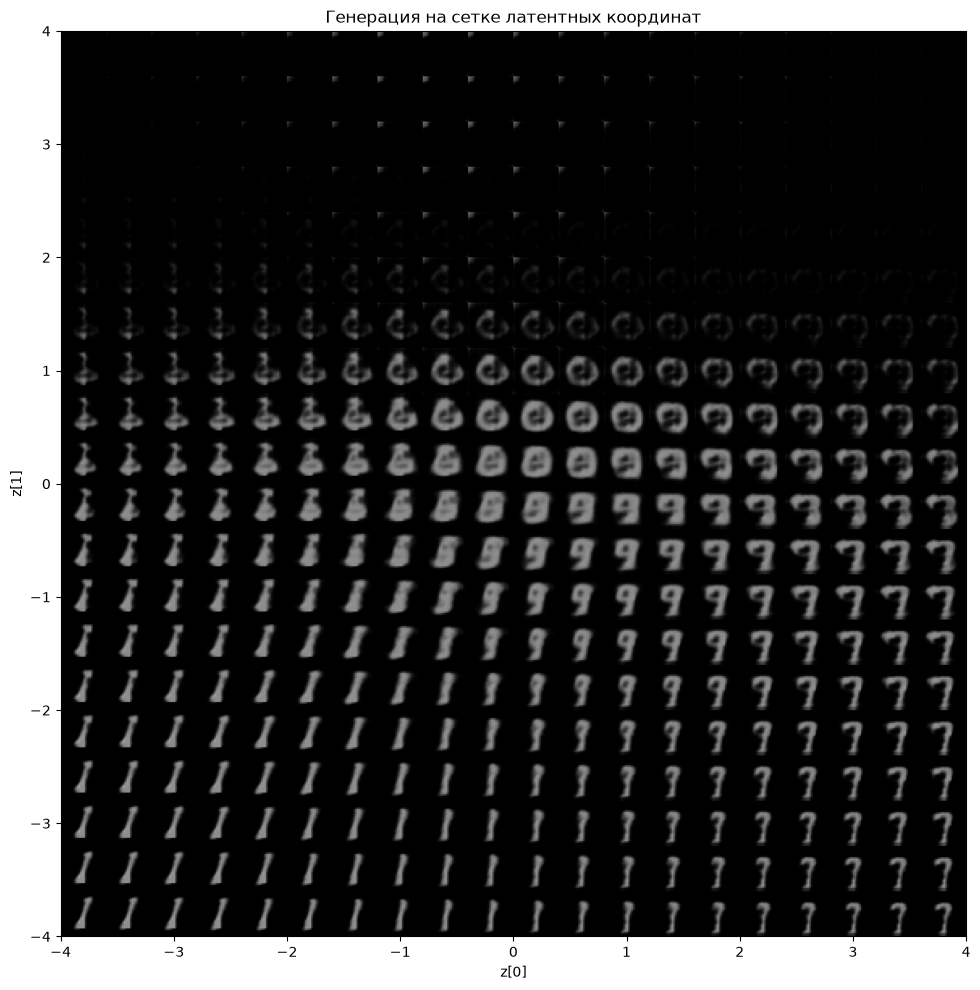

In [6]:
scale = 4.0
grid_size = 20
digit_size = 28

grid_x = np.linspace(-scale, scale, grid_size)
grid_y = np.linspace(scale, -scale, grid_size)
xx, yy = np.meshgrid(grid_x, grid_y)
latent_grid = np.column_stack((xx.ravel(), yy.ravel())).astype("float32")
generated = decoder.predict(latent_grid, batch_size=batch_size, verbose=0)
canvas = (
    generated.reshape(grid_size, grid_size, digit_size, digit_size)
    .transpose(0, 2, 1, 3)
    .reshape(grid_size * digit_size, grid_size * digit_size)
)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(
    canvas, cmap="gray", vmin=0, vmax=1,
    extent=(-scale, scale, -scale, scale),
)
ax.set_title("Генерация на сетке латентных координат")
ax.set_xlabel("z[0]")
ax.set_ylabel("z[1]")
fig.tight_layout()
plt.show()

## 7. Расположение тестовых цифр в latent space

Изображаем `z_mean`, чтобы рисунок не зависел от отдельного случайного
sampling. Цвет показывает истинную цифру. Метки используются только
для визуализации: VAE не обучался предсказывать классы.

Выраженные группы могут указывать на структуру представления, но сами
по себе не измеряют accuracy или качество генерации.

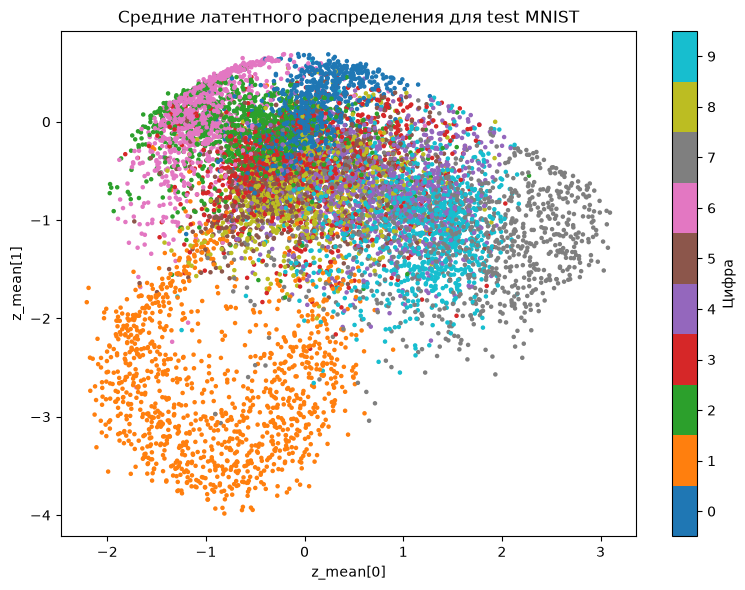

In [7]:
z_mean_test, _, _ = encoder.predict(x_test, batch_size=batch_size, verbose=0)
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    z_mean_test[:, 0], z_mean_test[:, 1], c=y_test,
    cmap="tab10", s=5, vmin=-0.5, vmax=9.5,
)
colorbar = fig.colorbar(scatter, ax=ax, ticks=np.arange(10))
colorbar.set_label("Цифра")
ax.set_title("Средние латентного распределения для test MNIST")
ax.set_xlabel("z_mean[0]")
ax.set_ylabel("z_mean[1]")
fig.tight_layout()
plt.show()

## 8. Интерпретация и ограничения

После одной эпохи test loss составляет **175.975647**:
reconstruction loss — **171.279160**, KL divergence — **4.696514**.
MSE восстановления через средний код — **0.054560**.
Основной численный вклад в общую потерю даёт восстановление изображения.

На сетке decoder создаёт размытые формы цифр, а в верхней части
пространства многие изображения почти пустые. На рисунке `z_mean`
единицы образуют заметную группу, но большинство других классов
перекрываются. Это ограниченное представление после одной эпохи,
а не свидетельство качественного разделения всех цифр.

KL divergence приближает распределение encoder к prior, а reconstruction
loss требует сохранять информацию об изображении. При обучении модель
ищет баланс между этими требованиями. Test loss оценивается со случайным
кодом; MSE через `z_mean` вычисляется отдельно.
Одна эпоха, один seed и двумерный код ограничивают выводы о качестве.
